In [43]:
import time
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import ccxt
from itertools import combinations
from statsmodels.tsa.stattools import coint
from scipy.stats import ttest_rel

pd.set_option("display.width", 140)

In [44]:
UNIVERSE = [
    "BTC", "ETH", "SOL", "BNB", "XRP", "DOGE", "ADA", "LINK", "AVAX", "DOT",
    "LTC", "ATOM", "AAVE", "UNI", "ARB", "OP", "SUI", "NEAR", "ALGO", "FIL"
]
SYMBOLS = [f"{coin}/USD" for coin in UNIVERSE]

In [ ]:
exchange = ccxt.coinbase()
markets = exchange.load_markets()

symbols = [f"{coin}/USD" for coin in UNIVERSE if f"{coin}/USD" in markets]
pairs = list(combinations(symbols, 2))
print(f"{len(symbols)} coins available, {len(pairs)} candidate pairs")

20 coins available, 190 candidate pairs


In [46]:
def to_df(data, symbol):
    df = pd.DataFrame(data, columns=["timestamp", "open", "high", "low", "close", "volume"])
    df["timestamp"] = pd.to_datetime(df["timestamp"], unit="ms")
    df = df[["timestamp", "close"]].copy()
    df = df.rename(columns={"close": symbol})
    return df

In [ ]:
exchange = ccxt.coinbase({
    "enableRateLimit": True,
    "timeout": 30000,  
})

def fetch_ohlcv_history(exchange, symbol, timeframe, since_ms, limit=300, max_retries=5):
    all_rows = []
    since = since_ms
    now_ms = exchange.milliseconds()

    while since < now_ms:
        batch = None
        for attempt in range(max_retries):
            try:
                batch = exchange.fetch_ohlcv(symbol, timeframe=timeframe, since=since, limit=limit)
                break
            except (ccxt.RequestTimeout, ccxt.NetworkError) as e:
                if attempt == max_retries - 1:
                    raise
                time.sleep(2 ** attempt)

        if not batch:
            break

        all_rows.extend(batch)
        since = batch[-1][0] + 1

    return all_rows

In [ ]:
YEARS_OF_HISTORY = 5 
TIMEFRAME = "1h"

since_dt = pd.Timestamp.utcnow() - pd.DateOffset(years=YEARS_OF_HISTORY)
HISTORY_SINCE = exchange.parse8601(since_dt.strftime("%Y-%m-%dT%H:%M:%SZ"))

prices = None
for coin in UNIVERSE:
    symbol = f"{coin}/USD"
    if symbol not in markets:
        continue
    data = fetch_ohlcv_history(exchange, symbol, timeframe=TIMEFRAME, since_ms=HISTORY_SINCE)
    if not data:
        continue
    df = to_df(data, coin)
    prices = df if prices is None else prices.merge(df, on="timestamp", how="inner")

prices = prices.sort_values("timestamp").reset_index(drop=True)
print(f"{len(prices)} aligned hourly bars, {prices['timestamp'].min()} -> {prices['timestamp'].max()}")

/var/folders/74/lqx4_3w16sz74ftgv_mn1ytr0000gn/T/ipykernel_60606/2707846789.py:4: Pandas4Warning: Timestamp.utcnow is deprecated and will be removed in a future version. Use Timestamp.now('UTC') instead.
  since_dt = pd.Timestamp.utcnow() - pd.DateOffset(years=YEARS_OF_HISTORY)


BNB batch size: 0
43808 aligned hourly bars, 2021-08-01 04:00:00 -> 2026-08-01 03:00:00


In [51]:
available_assets = [c for c in UNIVERSE if c in prices.columns]
symbols = [f"{c}/USD" for c in available_assets]
pairs = list(combinations(symbols, 2))

In [53]:
TRAIN_FRAC = 0.7

split_idx = int(len(prices) * TRAIN_FRAC)
train_prices = prices.iloc[:split_idx].reset_index(drop=True)
test_prices = prices.iloc[split_idx:].reset_index(drop=True)

print(f"Train: {train_prices['timestamp'].min()} -> {train_prices['timestamp'].max()}  ({len(train_prices)} bars)")
print(f"Test:  {test_prices['timestamp'].min()} -> {test_prices['timestamp'].max()}  ({len(test_prices)} bars)")

Train: 2021-08-01 04:00:00 -> 2025-01-30 02:00:00  (30665 bars)
Test:  2025-01-30 03:00:00 -> 2026-08-01 03:00:00  (13143 bars)


In [54]:
def align_pair_prices(prices, asset_a, asset_b):
    out = prices[["timestamp", asset_a, asset_b]].dropna().copy()
    out = out.sort_values("timestamp").reset_index(drop=True)
    return out

In [55]:
def estimate_ols_spread(df, asset_a, asset_b):
    """
    Fit the hedge ratio via OLS (used ONLY on the train set) and run the
    Engle-Granger cointegration test on the two log-price series.
    Two nonstationary series can produce a highly significant OLS slope
    just because both trend -- that p-value is NOT a cointegration test,
    so we report the Engle-Granger p-value instead.
    """
    out = df.copy()
    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])

    X = sm.add_constant(out[f"log_{asset_b}"])
    y = out[f"log_{asset_a}"]
    model = sm.OLS(y, X).fit()

    alpha = model.params["const"]
    beta = model.params[f"log_{asset_b}"]
    corr = out[[f"log_{asset_a}", f"log_{asset_b}"]].corr().iloc[0, 1]
    out["spread"] = model.resid

    eg_stat, eg_pvalue, eg_crit = coint(out[f"log_{asset_a}"], out[f"log_{asset_b}"])

    return out, alpha, beta, corr, eg_pvalue

In [56]:
def apply_fixed_spread(df, asset_a, asset_b, alpha, beta):
    """
    Build the spread on a NEW sample (e.g. the test set) using an alpha/beta
    that was already estimated elsewhere (the train set). No refitting here,
    so no look-ahead when this is used out-of-sample.
    """
    out = df.copy()
    out[f"log_{asset_a}"] = np.log(out[asset_a])
    out[f"log_{asset_b}"] = np.log(out[asset_b])
    out["spread"] = out[f"log_{asset_a}"] - (alpha + beta * out[f"log_{asset_b}"])
    return out

In [57]:
def spread_half_life(spread):
    s = pd.Series(spread).dropna()
    lag = s.shift(1)
    diff = s - lag
    tmp = pd.concat([diff, lag], axis=1).dropna()
    tmp.columns = ["diff", "lag"]
    if len(tmp) < 5:
        return np.nan
    model = sm.OLS(tmp["diff"], sm.add_constant(tmp["lag"])).fit()
    lam = model.params["lag"]
    if lam >= 0:
        return np.nan
    return -np.log(2) / lam

In [58]:
def spread_crossings(z, threshold=2.0):
    z = pd.Series(z).dropna()
    if len(z) < 2:
        return 0
    upper = ((z.shift(1) < threshold) & (z >= threshold)).sum()
    lower = ((z.shift(1) > -threshold) & (z <= -threshold)).sum()
    return int(upper + lower)

In [ ]:
def pair_summary(prices, asset_a, asset_b, crossing_z=2.0):
    df, alpha, beta, corr, eg_pvalue = estimate_ols_spread(prices, asset_a, asset_b)

    spread = df["spread"].dropna()
    spread_vol = spread.std()
    hl = spread_half_life(spread)

    z = (spread - spread.mean()) / spread.std()
    crossings = spread_crossings(z, threshold=crossing_z)

    return pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Asset_A": asset_a,
        "Asset_B": asset_b,
        "Corr": corr,
        "EG_Coint_Pvalue": eg_pvalue, 
        "Alpha": alpha,
        "Beta": beta,
        "Spread Vol": spread_vol,
        "Half_life": hl,
        "Z_score Crossings": crossings
    })

In [ ]:
candidate_rows = []
for a, b in pairs:
    candidate_rows.append(pair_summary(train_prices, a.split("/")[0], b.split("/")[0]))

pair_table = pd.DataFrame(candidate_rows).sort_values("EG_Coint_Pvalue")

result = pair_table.query("Corr > 0.8")
result = result.query("EG_Coint_Pvalue < 0.05")  
result = result.sort_values(by="Half_life")
result = result.sort_values(by="Z_score Crossings", ascending=False)

selected_pairs = result.reset_index(drop=True)
print(f"{len(selected_pairs)} pairs selected on the train period")
selected_pairs.head(10)

2 pairs selected on the train period


,Pair,Asset_A,Asset_B,Corr,EG_Coint_Pvalue,Alpha,Beta,Spread Vol,Half_life,Z_score Crossings
0,SOL/LINK,SOL,LINK,0.851891,0.021478,0.385459,1.537880,0.483900,1477.911041,27
1,DOT/FIL,DOT,FIL,0.974309,0.000291,0.679635,0.702268,0.147458,497.747468,21


In [61]:
def rolling_zscore(series, window=25):
    mean = series.rolling(window).mean()
    std = series.rolling(window).std()
    return (series - mean) / std

In [62]:
def build_zscore_positions(z, entry_z=2.0, exit_z=0.25):
    position = 0
    positions = []
    for val in z:
        if pd.isna(val):
            positions.append(0)
            continue
        if position == 0:
            if val < -entry_z:
                position = 1
            elif val > entry_z:
                position = -1
        elif position == 1:
            if val > -exit_z:
                position = 0
        elif position == -1:
            if val < exit_z:
                position = 0
        positions.append(position)
    return pd.Series(positions, index=z.index)

In [63]:
def build_bollinger_positions(spread, window=25, band_k=1.0):
    mid = spread.rolling(window).mean()
    std = spread.rolling(window).std()
    upper = mid + band_k * std
    lower = mid - band_k * std

    position = 0
    positions = []
    for s, m, u, l in zip(spread, mid, upper, lower):
        if pd.isna(s) or pd.isna(m) or pd.isna(u) or pd.isna(l):
            positions.append(0)
            continue
        if position == 0:
            if s < l:
                position = 1
            elif s > u:
                position = -1
        elif position == 1:
            if s >= m:
                position = 0
        elif position == -1:
            if s <= m:
                position = 0
        positions.append(position)

    out = pd.Series(positions, index=spread.index)
    return out, mid, upper, lower

In [ ]:
ANN_FACTOR_HOURLY = np.sqrt(24 * 365)


def backtest_pair_strategy(
    prices, asset_a, asset_b, alpha, beta,
    strategy="zscore", window=25, entry_z=2.0, exit_z=0.25, band_k=1.0, fee_bps=20.0
):
    """
    alpha, beta: fixed hedge-ratio coefficients estimated on the TRAIN set.
    They are applied unchanged here, whether `prices` is the train or test slice.
    Returns:
        bt_df: full backtest DataFrame, indexed by timestamp
        metrics: one-row summary Series
    """
    df = align_pair_prices(prices, asset_a, asset_b)
    df = apply_fixed_spread(df, asset_a, asset_b, alpha, beta)

    df["spread_mean"] = df["spread"].rolling(window).mean()
    df["spread_std"] = df["spread"].rolling(window).std()

    if strategy == "zscore":
        df["zscore"] = rolling_zscore(df["spread"], window=window)
        df["position"] = build_zscore_positions(df["zscore"], entry_z=entry_z, exit_z=exit_z)
    elif strategy == "bollinger":
        df["position"], df["bb_mid"], df["bb_upper"], df["bb_lower"] = build_bollinger_positions(
            df["spread"], window=window, band_k=band_k
        )
    else:
        raise ValueError("strategy must be 'zscore' or 'bollinger'")

    # ???
    gross = 1 + abs(beta)
    df["w_a"] = df["position"] / gross
    df["w_b"] = -beta * df["position"] / gross

    df[f"ret_{asset_a}"] = df[asset_a].pct_change()
    df[f"ret_{asset_b}"] = df[asset_b].pct_change()

    raw_ret = (
        df["w_a"].shift(1) * df[f"ret_{asset_a}"] +
        df["w_b"].shift(1) * df[f"ret_{asset_b}"]
    )

    # ???
    turnover = (
        df["w_a"].diff().abs().fillna(0) +
        df["w_b"].diff().abs().fillna(0)
    )
    df["turnover"] = turnover

    cost_per_turn = fee_bps / 10000.0
    df["strategy_ret"] = raw_ret - turnover * cost_per_turn

    df = df.set_index("timestamp")   # keep a real time index -> safe alignment downstream
    df["equity"] = (1 + df["strategy_ret"].fillna(0)).cumprod()

    r = df["strategy_ret"].dropna()
    sharpe = (r.mean() / r.std()) * ANN_FACTOR_HOURLY if r.std() not in (0,) and not np.isnan(r.std()) else np.nan
    max_dd = (df["equity"] / df["equity"].cummax() - 1).min()
    cum_ret = df["equity"].iloc[-1] - 1 if len(df) else np.nan
    trades = (df["position"].diff().fillna(0) != 0).sum()

    metrics = pd.Series({
        "Pair": f"{asset_a}/{asset_b}",
        "Strategy": strategy,
        "Alpha": alpha,
        "Beta": beta,
        "Sharpe": sharpe,
        "Cumulative Return": cum_ret,
        "Max Drawdown": max_dd,
        "Trades": int(trades),
        "Avg Turnover/Bar": turnover.mean(),
        "Mean Hourly Return": r.mean(),
        "Vol Hourly": r.std(),
    })
    return df, metrics

In [65]:
FEE_BPS_MAIN = 20.0   # course assumption for crypto market orders -- lead with this
WINDOW = 25
Z_ENTRY = 2.0
Z_EXIT = 0.25
BB_K = 1.0


def run_pairs(prices_slice, selected_pairs, strategy, param_value, fee_bps, window=WINDOW, exit_z=Z_EXIT):
    """Backtest every selected pair (with its fixed train alpha/beta) on prices_slice."""
    bts = {}
    ret_series = {}
    metrics_rows = []
    for _, row in selected_pairs.iterrows():
        a, b = row["Asset_A"], row["Asset_B"]
        kwargs = dict(window=window, fee_bps=fee_bps)
        if strategy == "zscore":
            kwargs.update(entry_z=param_value, exit_z=exit_z)
        else:
            kwargs.update(band_k=param_value)
        bt, m = backtest_pair_strategy(
            prices_slice, a, b, alpha=row["Alpha"], beta=row["Beta"], strategy=strategy, **kwargs
        )
        pair_name = f"{a}/{b}"
        bts[pair_name] = bt
        ret_series[pair_name] = bt["strategy_ret"].rename(pair_name)
        metrics_rows.append(m)
    return bts, ret_series, pd.DataFrame(metrics_rows)

In [66]:
def equal_vol_weights_from_returns(ret_series):
    rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")
    vols = rets.std()
    inv_vol = 1 / vols.replace(0, np.nan)
    weights = inv_vol / inv_vol.sum()
    return weights, rets

In [67]:
# ---- Train: backtest every selected pair and derive fixed weights ----
z_train_bts, z_train_rets, z_train_metrics = run_pairs(train_prices, selected_pairs, "zscore", Z_ENTRY, FEE_BPS_MAIN)
bb_train_bts, bb_train_rets, bb_train_metrics = run_pairs(train_prices, selected_pairs, "bollinger", BB_K, FEE_BPS_MAIN)

z_weights, _ = equal_vol_weights_from_returns(z_train_rets)
bb_weights, _ = equal_vol_weights_from_returns(bb_train_rets)

print("Z-score weights estimated on train (head):")
print(z_weights.sort_values(ascending=False).head())

print("Bollinger weights estimated on train (head):")
print(bb_weights.sort_values(ascending=False).head())

Z-score weights estimated on train (head):
DOT/FIL     0.522824
SOL/LINK    0.477176
dtype: float64
Bollinger weights estimated on train (head):
DOT/FIL     0.521903
SOL/LINK    0.478097
dtype: float64


In [68]:
def apply_fixed_weights(ret_series, weights):
    rets = pd.concat(ret_series.values(), axis=1, join="inner").dropna(how="any")
    w = weights.reindex(rets.columns).fillna(0.0)
    if w.sum() > 0:
        w = w / w.sum()   # renormalize if some train pairs are missing from test alignment
    port_ret = rets.mul(w, axis=1).sum(axis=1)
    return port_ret, w, rets

In [69]:
def portfolio_metrics_hourly(port_ret):
    port_ret = port_ret.dropna()
    equity = (1 + port_ret.fillna(0)).cumprod()
    vol = port_ret.std()
    sharpe = np.nan if vol == 0 or np.isnan(vol) else (port_ret.mean() / vol) * ANN_FACTOR_HOURLY
    max_dd = (equity / equity.cummax() - 1).min()
    return {
        "Sharpe (hourly)": sharpe,
        "Cumulative Return": equity.iloc[-1] - 1 if len(equity) else np.nan,
        "Max Drawdown": max_dd,
        "N Obs": len(port_ret),
    }

In [70]:
# ---- Test: backtest each selected pair using its FIXED train alpha/beta ----
z_test_bts, z_test_rets, z_test_metrics = run_pairs(test_prices, selected_pairs, "zscore", Z_ENTRY, FEE_BPS_MAIN)
bb_test_bts, bb_test_rets, bb_test_metrics = run_pairs(test_prices, selected_pairs, "bollinger", BB_K, FEE_BPS_MAIN)

# ---- Apply the FIXED train weights (no re-estimation on test) ----
z_port_ret, z_w_applied, z_rets_aligned = apply_fixed_weights(z_test_rets, z_weights)
bb_port_ret, bb_w_applied, bb_rets_aligned = apply_fixed_weights(bb_test_rets, bb_weights)

test_summary = pd.DataFrame({
    "Z-score": portfolio_metrics_hourly(z_port_ret),
    "Bollinger": portfolio_metrics_hourly(bb_port_ret),
}).T
print(f"Out-of-sample results at {FEE_BPS_MAIN:.0f} bps costs:")
test_summary

Out-of-sample results at 20 bps costs:


,Sharpe (hourly),Cumulative Return,Max Drawdown,N Obs
Z-score,-4.843111,-0.736739,-0.739157,13142.0
Bollinger,-7.332659,-0.907960,-0.908549,13142.0


In [ ]:
def portfolio_turnover(test_bts, weights):
    per_pair_turnover = {p: bt["turnover"].mean() for p, bt in test_bts.items()}
    per_pair_turnover = pd.Series(per_pair_turnover)
    w = weights.reindex(per_pair_turnover.index).fillna(0)
    port_level = (per_pair_turnover * w).sum()
    return per_pair_turnover.sort_values(ascending=False), port_level


z_pair_turnover, z_port_turnover = portfolio_turnover(z_test_bts, z_w_applied)
bb_pair_turnover, bb_port_turnover = portfolio_turnover(bb_test_bts, bb_w_applied)

print(f"Z-score portfolio avg turnover/bar: {z_port_turnover:.4f}")
print(f"Bollinger portfolio avg turnover/bar: {bb_port_turnover:.4f}")
print()
print("Top-turnover pairs (Z-score):")
print(z_pair_turnover.head())
print()

# ???
print("Top-turnover pairs (Bollinger):")
print(bb_port_turnover)

Z-score portfolio avg turnover/bar: 0.0657
Bollinger portfolio avg turnover/bar: 0.1174

Top-turnover pairs (Z-score):
DOT/FIL     0.065738
SOL/LINK    0.065586
dtype: float64

Top-turnover pairs (Bollinger):
0.11741089697067189


,Strategy,Fee_bps,Sharpe (hourly),Cumulative Return,Max Drawdown,N Obs
0,Z-score,0,1.512234,0.478028,-0.161460,13142
1,Bollinger,0,2.241550,1.012399,-0.166467,13142
2,Z-score,5,-0.056653,-0.039637,-0.204307,13142
3,Bollinger,5,-0.111459,-0.069047,-0.249576,13142
4,Z-score,7,-0.690279,-0.191794,-0.252587,13142
5,Bollinger,7,-1.064546,-0.316111,-0.353298,13142
6,Z-score,10,-1.645342,-0.376068,-0.387542,13142
7,Bollinger,10,-2.503486,-0.569431,-0.579018,13142
8,Z-score,15,-3.244189,-0.594690,-0.598814,13142
9,Bollinger,15,-4.916829,-0.800906,-0.802280,13142


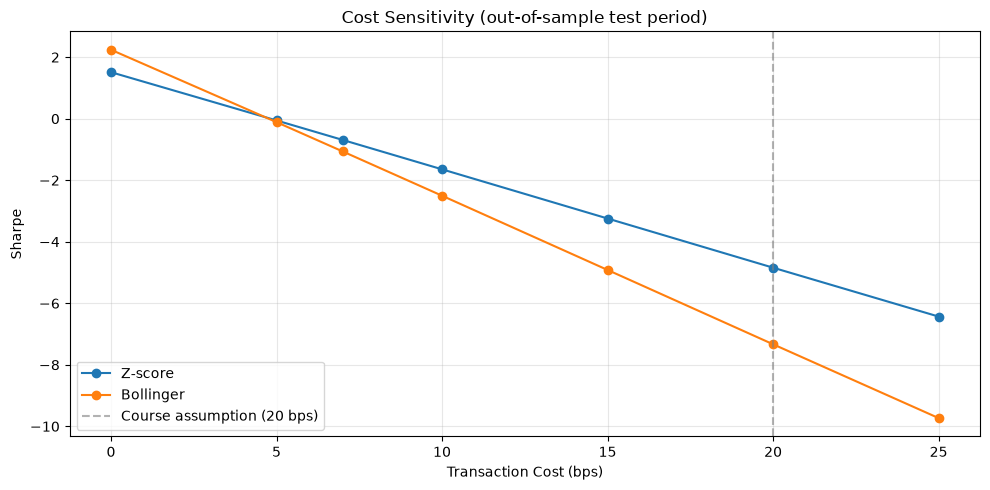

In [ ]:
fee_grid = [0, 5, 7, 10, 15, 20, 25]   

cost_rows = []
for fee in fee_grid:
    _, z_rs, _ = run_pairs(test_prices, selected_pairs, "zscore", Z_ENTRY, fee)
    z_ret, _, _ = apply_fixed_weights(z_rs, z_weights)
    m = portfolio_metrics_hourly(z_ret)
    cost_rows.append({"Strategy": "Z-score", "Fee_bps": fee, **m})

    _, bb_rs, _ = run_pairs(test_prices, selected_pairs, "bollinger", BB_K, fee)
    bb_ret, _, _ = apply_fixed_weights(bb_rs, bb_weights)
    m = portfolio_metrics_hourly(bb_ret)
    cost_rows.append({"Strategy": "Bollinger", "Fee_bps": fee, **m})

cost_df = pd.DataFrame(cost_rows)
display(cost_df)

plt.figure(figsize=(10, 5))
for strat in ["Z-score", "Bollinger"]:
    sub = cost_df[cost_df["Strategy"] == strat].sort_values("Fee_bps")
    plt.plot(sub["Fee_bps"], sub["Sharpe (hourly)"], marker="o", label=strat)
plt.axvline(20, color="gray", linestyle="--", alpha=0.6, label="Course assumption (20 bps)")
plt.title("Cost Sensitivity (out-of-sample test period)")
plt.xlabel("Transaction Cost (bps)")
plt.ylabel("Sharpe")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

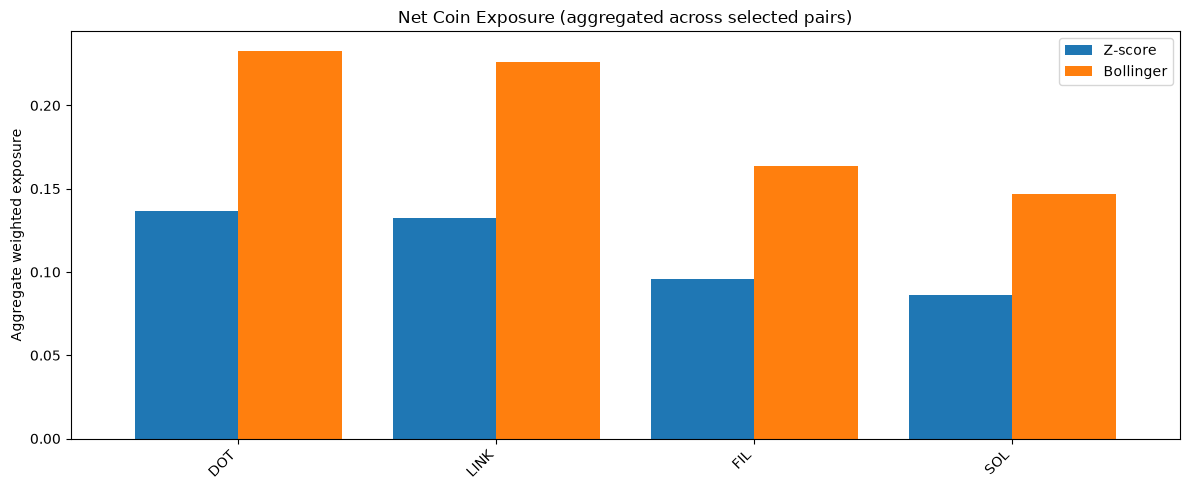

,Z-score,Bollinger
DOT,0.136823,0.232855
LINK,0.132400,0.226074
FIL,0.096087,0.163526
SOL,0.086093,0.147004


In [73]:
def coin_exposure(test_bts, weights):
    exposure = {}
    for pair_name, w in weights.items():
        if w == 0 or pair_name not in test_bts:
            continue
        a, b = pair_name.split("/")
        bt = test_bts[pair_name]
        exposure[a] = exposure.get(a, 0.0) + w * bt["w_a"].abs().mean()
        exposure[b] = exposure.get(b, 0.0) + w * bt["w_b"].abs().mean()
    return pd.Series(exposure).sort_values(ascending=False)


z_coin_exposure = coin_exposure(z_test_bts, z_w_applied)
bb_coin_exposure = coin_exposure(bb_test_bts, bb_w_applied)

coin_exp_df = pd.concat(
    [z_coin_exposure.rename("Z-score"), bb_coin_exposure.rename("Bollinger")], axis=1
).fillna(0).sort_values("Z-score", ascending=False)

ax = coin_exp_df.plot(kind="bar", figsize=(12, 5), width=0.8)
ax.set_title("Net Coin Exposure (aggregated across selected pairs)")
ax.set_ylabel("Aggregate weighted exposure")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

coin_exp_df.head(10)

In [74]:
def hourly_to_daily(hourly_ret):
    equity = (1 + hourly_ret.fillna(0)).cumprod()
    daily_equity = equity.resample("1D").last().dropna()
    daily_ret = daily_equity.pct_change().dropna()
    return daily_ret

In [75]:
def daily_portfolio_metrics(daily_ret):
    daily_ret = daily_ret.dropna()
    equity = (1 + daily_ret.fillna(0)).cumprod()
    vol = daily_ret.std()
    sharpe = np.nan if vol == 0 or np.isnan(vol) else (daily_ret.mean() / vol) * np.sqrt(365)
    max_dd = (equity / equity.cummax() - 1).min()
    return {
        "Sharpe (daily)": sharpe,
        "Cumulative Return": equity.iloc[-1] - 1 if len(equity) else np.nan,
        "Max Drawdown": max_dd,
        "N Days": len(daily_ret),
    }

In [76]:
def benchmark_stats(port_daily_ret, btc_daily_ret):
    aligned = pd.concat(
        [port_daily_ret.rename("port"), btc_daily_ret.rename("btc")], axis=1
    ).dropna()
    X = sm.add_constant(aligned["btc"])
    model = sm.OLS(aligned["port"], X).fit()
    return {
        "Corr_to_BTC": aligned["port"].corr(aligned["btc"]),
        "Beta_to_BTC": model.params["btc"],
        "Alpha_Annualized": model.params["const"] * 365,
        "Alpha_tstat": model.tvalues["const"],
    }

In [77]:
btc_test_prices = test_prices.set_index("timestamp")["BTC"]
btc_daily_ret = btc_test_prices.resample("1D").last().dropna().pct_change().dropna()

z_daily_ret = hourly_to_daily(z_port_ret)
bb_daily_ret = hourly_to_daily(bb_port_ret)

final_rows = {}
for name, daily_ret in [("Z-score", z_daily_ret), ("Bollinger", bb_daily_ret)]:
    row = daily_portfolio_metrics(daily_ret)
    row.update(benchmark_stats(daily_ret, btc_daily_ret))
    final_rows[name] = row

final_summary = pd.DataFrame(final_rows).T
print(f"Final out-of-sample summary at {FEE_BPS_MAIN:.0f} bps, daily-aggregated:")
final_summary

Final out-of-sample summary at 20 bps, daily-aggregated:


,Sharpe (daily),Cumulative Return,Max Drawdown,N Days,Corr_to_BTC,Beta_to_BTC,Alpha_Annualized,Alpha_tstat
Z-score,-5.596153,-0.736739,-0.733989,548.0,0.041786,0.014915,-0.871810,-6.825464
Bollinger,-8.895540,-0.907960,-0.906645,548.0,0.026006,0.010470,-1.567095,-10.871233


N pairs compared: 2
TtestResult(statistic=np.float64(18.17416614890695), pvalue=np.float64(0.034993543367784465), df=np.int64(1))


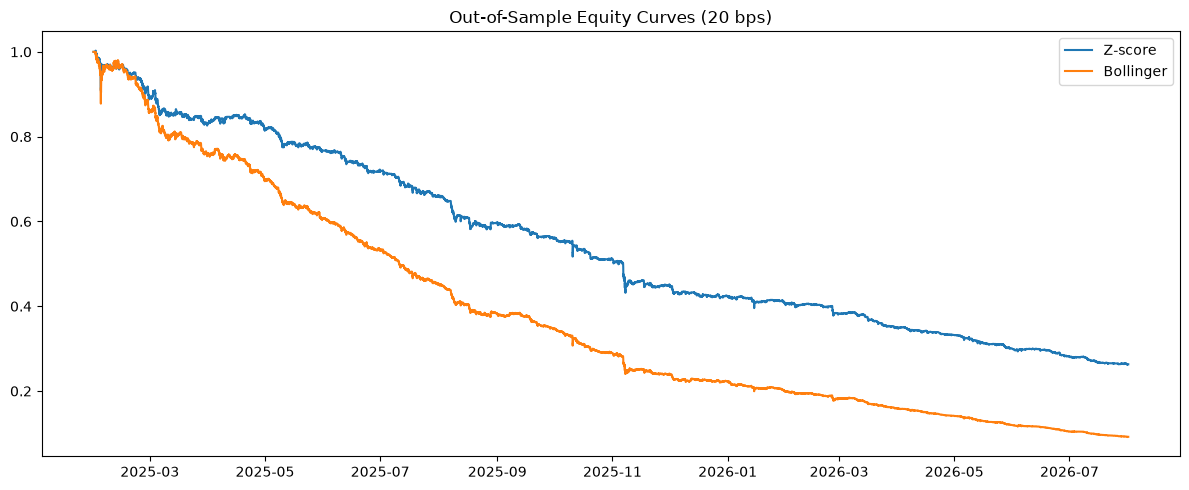

In [ ]:
# ???
paired = z_test_metrics.set_index("Pair")["Sharpe"].rename("Sharpe_Z").to_frame()
paired["Sharpe_BB"] = bb_test_metrics.set_index("Pair")["Sharpe"]
paired = paired.dropna()

print(f"N pairs compared: {len(paired)}")
print(ttest_rel(paired["Sharpe_Z"], paired["Sharpe_BB"]))

plt.figure(figsize=(12, 5))
plt.plot((1 + z_port_ret.fillna(0)).cumprod(), label="Z-score")
plt.plot((1 + bb_port_ret.fillna(0)).cumprod(), label="Bollinger")
plt.title(f"Out-of-Sample Equity Curves ({FEE_BPS_MAIN:.0f} bps)")
plt.legend()
plt.tight_layout()
plt.show()

In [79]:
LOOKBACK = len(train_prices)      # bars used to estimate alpha/beta each refit
REFIT_EVERY = 24 * 30             # refit monthly

def rolling_beta_pair_returns(prices, asset_a, asset_b, strategy, param_value,
                               lookback=LOOKBACK, refit_every=REFIT_EVERY, fee_bps=FEE_BPS_MAIN,
                               window=WINDOW, exit_z=Z_EXIT):
    """Walk forward: refit alpha/beta on the trailing `lookback` bars every `refit_every`
    bars, then trade the following segment with those fixed coefficients (no look-ahead
    within any segment)."""
    segments = []
    start = lookback
    while start < len(prices):
        train_slice = prices.iloc[start - lookback:start]
        trade_slice = prices.iloc[start:start + refit_every]
        if len(trade_slice) < window + 2:
            break
        _, alpha, beta, _, _ = estimate_ols_spread(
            align_pair_prices(train_slice, asset_a, asset_b), asset_a, asset_b
        )
        kwargs = dict(window=window, fee_bps=fee_bps)
        if strategy == "zscore":
            kwargs.update(entry_z=param_value, exit_z=exit_z)
        else:
            kwargs.update(band_k=param_value)
        bt, _ = backtest_pair_strategy(trade_slice, asset_a, asset_b, alpha=alpha, beta=beta,
                                        strategy=strategy, **kwargs)
        segments.append(bt["strategy_ret"])
        start += refit_every
    if not segments:
        return pd.Series(dtype=float)
    return pd.concat(segments)

# Example usage on one pair (kept small on purpose -- expensive to run for all pairs):
example_pair = selected_pairs.iloc[0]
rolling_ret = rolling_beta_pair_returns(prices, example_pair["Asset_A"], example_pair["Asset_B"],
                                         "zscore", Z_ENTRY)
portfolio_metrics_hourly(rolling_ret)

{'Sharpe (hourly)': np.float64(-4.032203870106749),
 'Cumulative Return': np.float64(-0.7718572645146318),
 'Max Drawdown': np.float64(-0.7739461888968852),
 'N Obs': 13124}